<a href="https://colab.research.google.com/github/kunapareddysriram2007-cmyk/Deep_Learning/blob/main/VisionPort_End_to_End_Skill_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install ultralytics opencv-python

In [ ]:
import torch
import cv2

from ultralytics import YOLO

print("PyTorch:", torch.__version__)
print("OpenCV:", cv2.__version__)
print("CUDA Available:", torch.cuda.is_available())

print("VisionPort libraries loaded successfully!")

PyTorch: 2.14.1+cu130
OpenCV: 4.14.0
CUDA Available: True
VisionPort libraries loaded successfully!


In [ ]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")

print("YOLO model loaded successfully!")

YOLO model loaded successfully!


In [ ]:
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"

model.to(device)

print("Running on:", device)

Running on: cuda


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving traffic photo.jpg to traffic photo (1).jpg


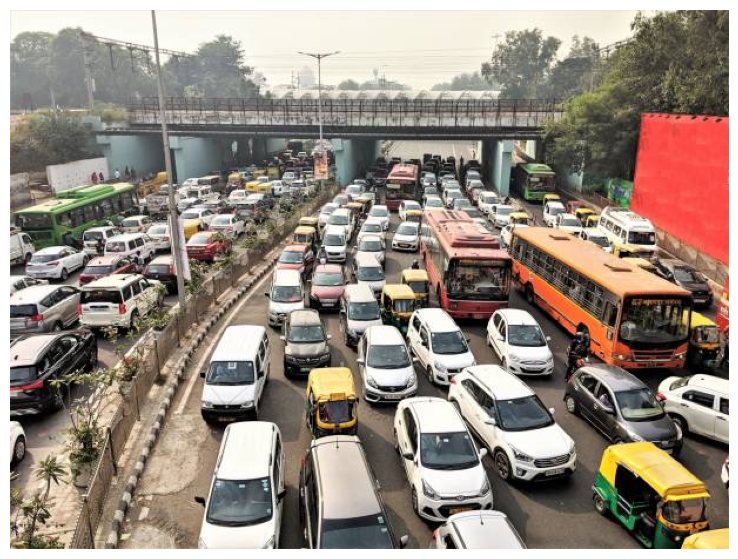

In [ ]:
import cv2
import matplotlib.pyplot as plt

image_path = list(uploaded.keys())[0]

image = cv2.imread(image_path)

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 7))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
results = model.predict(
    source=image,
    conf=0.25,
    device=device
)

print("Detection completed!")


0: 480x640 19 cars, 8 buss, 1 truck, 7.9ms
Speed: 2.8ms preprocess, 7.9ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)
Detection completed!


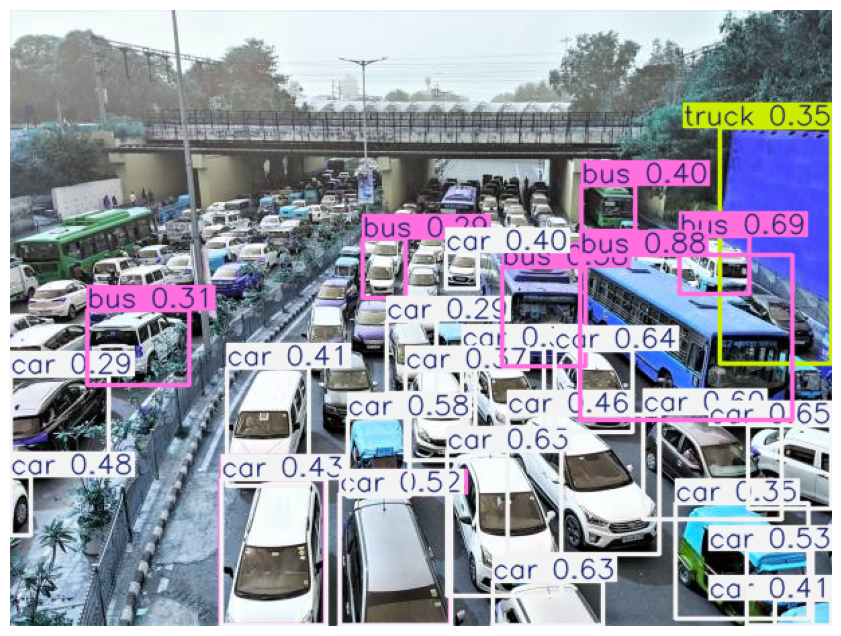

In [ ]:
result_image = results[0].plot()

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(result_image, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

In [ ]:
vehicle_classes = ["car", "motorcycle", "bus", "truck"]

vehicle_count = {}

for result in results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        if class_name in vehicle_classes:
            vehicle_count[class_name] = vehicle_count.get(class_name, 0) + 1

print("Vehicle Detection Summary")

for vehicle, count in vehicle_count.items():
    print(vehicle, ":", count)

print("Total Vehicles:", sum(vehicle_count.values()))

Vehicle Detection Summary
bus : 8
car : 19
truck : 1
Total Vehicles: 28


In [ ]:
vehicle_classes = ["car", "motorcycle", "bus", "truck"]

detections = []

for result in results:
    for box in result.boxes:

        class_id = int(box.cls[0])
        class_name = model.names[class_id]

        if class_name in vehicle_classes:

            confidence = float(box.conf[0])

            x1, y1, x2, y2 = box.xyxy[0].tolist()

            detections.append({
                "vehicle": class_name,
                "confidence": round(confidence, 3),
                "bbox": [
                    round(x1, 2),
                    round(y1, 2),
                    round(x2, 2),
                    round(y2, 2)
                ]
            })

print(detections)

[{'vehicle': 'bus', 'confidence': 0.882, 'bbox': [424.61, 182.79, 582.21, 305.96]}, {'vehicle': 'bus', 'confidence': 0.692, 'bbox': [498.93, 168.29, 550.61, 211.56]}, {'vehicle': 'car', 'confidence': 0.649, 'bbox': [549.53, 309.35, 611.73, 371.83]}, {'vehicle': 'car', 'confidence': 0.639, 'bbox': [405.06, 253.26, 463.51, 314.55]}, {'vehicle': 'car', 'confidence': 0.632, 'bbox': [359.28, 425.57, 441.47, 458.81]}, {'vehicle': 'car', 'confidence': 0.626, 'bbox': [325.71, 328.65, 410.88, 436.97]}, {'vehicle': 'car', 'confidence': 0.598, 'bbox': [471.42, 300.84, 574.9, 379.9]}, {'vehicle': 'car', 'confidence': 0.582, 'bbox': [251.9, 303.93, 297.79, 362.97]}, {'vehicle': 'car', 'confidence': 0.527, 'bbox': [548.41, 402.28, 597.72, 458.11]}, {'vehicle': 'car', 'confidence': 0.515, 'bbox': [245.91, 360.68, 328.35, 458.77]}, {'vehicle': 'car', 'confidence': 0.482, 'bbox': [0.09, 347.75, 15.51, 391.29]}, {'vehicle': 'car', 'confidence': 0.463, 'bbox': [370.36, 301.32, 483.49, 405.45]}, {'vehicle

In [ ]:
import pandas as pd

df = pd.DataFrame(detections)

display(df)

,vehicle,confidence,bbox
0,bus,0.882,"[424.61, 182.79, 582.21, 305.96]"
1,bus,0.692,"[498.93, 168.29, 550.61, 211.56]"
2,car,0.649,"[549.53, 309.35, 611.73, 371.83]"
3,car,0.639,"[405.06, 253.26, 463.51, 314.55]"
4,car,0.632,"[359.28, 425.57, 441.47, 458.81]"
5,car,0.626,"[325.71, 328.65, 410.88, 436.97]"
6,car,0.598,"[471.42, 300.84, 574.9, 379.9]"
7,car,0.582,"[251.9, 303.93, 297.79, 362.97]"
8,car,0.527,"[548.41, 402.28, 597.72, 458.11]"
9,car,0.515,"[245.91, 360.68, 328.35, 458.77]"


In [ ]:
total_vehicles = len(detections)

average_confidence = (
    sum(d["confidence"] for d in detections) / total_vehicles
    if total_vehicles > 0 else 0
)

print("Total vehicles:", total_vehicles)
print("Average confidence:", round(average_confidence, 3))

Total vehicles: 28
Average confidence: 0.461


In [ ]:
import json

output = {
    "total_vehicles": len(detections),
    "detections": detections
}

json_data = json.dumps(output, indent=4)

print(json_data)

{
    "total_vehicles": 28,
    "detections": [
        {
            "vehicle": "bus",
            "confidence": 0.882,
            "bbox": [
                424.61,
                182.79,
                582.21,
                305.96
            ]
        },
        {
            "vehicle": "bus",
            "confidence": 0.692,
            "bbox": [
                498.93,
                168.29,
                550.61,
                211.56
            ]
        },
        {
            "vehicle": "car",
            "confidence": 0.649,
            "bbox": [
                549.53,
                309.35,
                611.73,
                371.83
            ]
        },
        {
            "vehicle": "car",
            "confidence": 0.639,
            "bbox": [
                405.06,
                253.26,
                463.51,
                314.55
            ]
        },
        {
            "vehicle": "car",
            "confidence": 0.632,
            "bbox":

In [ ]:
with open("visionport_results.json", "w") as file:
    json.dump(output, file, indent=4)

print("JSON file saved successfully!")

JSON file saved successfully!


## End-to-End deployment: ONNX, TensorRT, Triton and FastAPI

In [ ]:
# Export YOLO11n to ONNX with NMS included
onnx_path = model.export(format="onnx", imgsz=640, opset=17, simplify=True, nms=True, dynamic=False)
onnx_path = str(onnx_path)
print("ONNX model:", onnx_path)
print("Size (MB):", round(os.path.getsize(onnx_path) / 1024**2, 2))

In [ ]:
# Validate ONNX and inspect exact input/output names and dimensions
import onnx
onnx_model = onnx.load(onnx_path)
onnx.checker.check_model(onnx_model)
for item in onnx_model.graph.input:
    print("INPUT", item.name, [d.dim_value or d.dim_param for d in item.type.tensor_type.shape.dim])
for item in onnx_model.graph.output:
    print("OUTPUT", item.name, [d.dim_value or d.dim_param for d in item.type.tensor_type.shape.dim])

## Create the Triton model repository and FastAPI service

In [ ]:
from pathlib import Path
import shutil, os, zipfile

ROOT = Path("/content/visionport_deployment")
API = ROOT / "api"
MODEL = ROOT / "model_repository" / "vehicle_detector" / "1"
API.mkdir(parents=True, exist_ok=True)
MODEL.mkdir(parents=True, exist_ok=True)
shutil.copy2(onnx_path, MODEL / "model.onnx")

# Confirm names/shapes printed in the ONNX inspection cell before deployment.
config = """name: "vehicle_detector"
platform: "onnxruntime_onnx"
max_batch_size: 0
input [ { name: "images" data_type: TYPE_FP32 dims: [ 1, 3, 640, 640 ] } ]
output [ { name: "output0" data_type: TYPE_FP32 dims: [ 1, 300, 6 ] } ]
instance_group [ { kind: KIND_GPU count: 1 } ]
"""
(ROOT / "model_repository" / "vehicle_detector" / "config.pbtxt").write_text(config)

api = r"""import os
import cv2
import numpy as np
from fastapi import FastAPI, UploadFile, File, HTTPException
from fastapi.responses import JSONResponse
import tritonclient.http as httpclient

app = FastAPI(title="VisionPort API", version="1.0")
TRITON_URL = os.getenv("TRITON_URL", "triton:8000")
MODEL_NAME = os.getenv("TRITON_MODEL", "vehicle_detector")
CLASS_NAMES = {2: "car", 3: "motorcycle", 5: "bus", 7: "truck"}
SIZE = 640

def get_client():
    c = httpclient.InferenceServerClient(url=TRITON_URL)
    if not c.is_server_live():
        raise RuntimeError("Triton is not live")
    return c

@app.get("/health")
def health():
    try:
        c = get_client()
        return {"api": "ok", "triton": "ok", "model_ready": c.is_model_ready(MODEL_NAME)}
    except Exception as e:
        return JSONResponse(status_code=503, content={"api": "ok", "triton": "unavailable", "detail": str(e)})

@app.post("/detect")
async def detect(file: UploadFile = File(...), confidence: float = 0.25):
    raw = await file.read()
    image = cv2.imdecode(np.frombuffer(raw, np.uint8), cv2.IMREAD_COLOR)
    if image is None:
        raise HTTPException(400, "Invalid image")
    h, w = image.shape[:2]
    resized = cv2.resize(image, (SIZE, SIZE))
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    tensor = np.transpose(rgb.astype(np.float32) / 255.0, (2, 0, 1))[None, ...]
    inp = httpclient.InferInput("images", tensor.shape, "FP32")
    inp.set_data_from_numpy(tensor)
    out = httpclient.InferRequestedOutput("output0")
    try:
        result = get_client().infer(MODEL_NAME, [inp], outputs=[out])
        pred = result.as_numpy("output0")
    except Exception as e:
        raise HTTPException(503, f"Triton inference failed: {e}")
    detections = []
    for x1, y1, x2, y2, score, cls in np.asarray(pred).reshape(-1, 6):
        cid = int(cls)
        if float(score) < confidence or cid not in CLASS_NAMES:
            continue
        sx, sy = w / SIZE, h / SIZE
        detections.append({"vehicle": CLASS_NAMES[cid], "class_id": cid,
            "confidence": round(float(score), 4),
            "bbox_xyxy": [round(float(x1*sx),2), round(float(y1*sy),2),
                          round(float(x2*sx),2), round(float(y2*sy),2)]})
    counts = {n: sum(d["vehicle"] == n for d in detections) for n in CLASS_NAMES.values()}
    return {"project": "VisionPort", "image": file.filename,
            "total_vehicles": len(detections), "vehicle_counts": {k:v for k,v in counts.items() if v},
            "detections": detections}
"""
(API / "app.py").write_text(api)
(API / "requirements.txt").write_text("fastapi\nuvicorn[standard]\npython-multipart\nopencv-python-headless\nnumpy\ntritonclient[http]\n")
(API / "Dockerfile").write_text("""FROM python:3.11-slim
WORKDIR /app
RUN apt-get update && apt-get install -y --no-install-recommends libglib2.0-0 libgl1 && rm -rf /var/lib/apt/lists/*
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY app.py .
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
""")
(ROOT / "docker-compose.yml").write_text("""services:
  triton:
    image: nvcr.io/nvidia/tritonserver:24.08-py3
    command: ["tritonserver", "--model-repository=/models"]
    volumes:
      - ./model_repository:/models
    ports:
      - "8001:8000"
      - "8002:8001"
    deploy:
      resources:
        reservations:
          devices:
            - driver: nvidia
              count: all
              capabilities: [gpu]
  api:
    build: ./api
    environment:
      TRITON_URL: triton:8000
      TRITON_MODEL: vehicle_detector
    ports:
      - "8000:8000"
    depends_on:
      - triton
""")
(ROOT / "build_tensorrt.sh").write_text("""#!/usr/bin/env bash
set -euo pipefail
D=model_repository/vehicle_detector
trtexec --onnx="$D/1/model.onnx" --saveEngine="$D/1/model.plan" --fp16 --shapes=images:1x3x640x640
cat > "$D/config.pbtxt" <<'EOF'
name: "vehicle_detector"
platform: "tensorrt_plan"
max_batch_size: 0
input [ { name: "images" data_type: TYPE_FP32 dims: [ 1, 3, 640, 640 ] } ]
output [ { name: "output0" data_type: TYPE_FP32 dims: [ 1, 300, 6 ] } ]
instance_group [ { kind: KIND_GPU count: 1 } ]
EOF
echo "TensorRT engine created; restart Triton."
""")
os.chmod(ROOT / "build_tensorrt.sh", 0o755)
(ROOT / "README.txt").write_text("""VISIONPORT DEPLOYMENT

On a Linux NVIDIA GPU host with Docker, NVIDIA Container Toolkit and Docker Compose:
  docker compose up --build

FastAPI docs: http://localhost:8000/docs
Health:       http://localhost:8000/health
Detection:    POST /detect with multipart image field 'file'.

TensorRT: run ./build_tensorrt.sh in a compatible NVIDIA TensorRT environment,
then restart Triton. Build the engine on the target GPU; TensorRT plans are
hardware/software specific.

Colab is used for YOLO inference and ONNX export. Full Triton + TensorRT serving
requires a compatible Linux NVIDIA deployment host. Check ONNX names/shapes
printed in the notebook and adjust config.pbtxt/app.py if they differ.
""")

bundle = "/content/VisionPort_Deployment_Bundle.zip"
with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as z:
    for p in ROOT.rglob("*"):
        if p.is_file(): z.write(p, p.relative_to(ROOT.parent))
print("Deployment bundle ready:", bundle)

In [ ]:
from google.colab import files
files.download("/content/VisionPort_Deployment_Bundle.zip")

## Run and benchmark

In [ ]:
# On a compatible Linux NVIDIA GPU host, extract the bundle and run:
# docker compose up --build
# Open http://localhost:8000/docs and POST an image to /detect.
# For TensorRT, run ./build_tensorrt.sh then restart Triton.
# Colab is not assumed to provide Docker daemon/Triton server support.
print("PyTorch YOLO inference (ms):", round(pytorch_seconds * 1000, 2))
print("Triton benchmark on deployment host:")
print("perf_analyzer -m vehicle_detector -u localhost:8001 --concurrency-range 1:4")